# Phần 4 (Giai đoạn 3). Làm sạch và Đồng bộ Dữ liệu trong SQL Server (`4_data_cleaning.py`)

Notebook này trình bày chi tiết từng khối lệnh cấu thành nên tệp **`4_data_cleaning.py`**. Thay vì chạy gộp một hàm lớn khó kiểm tra trung gian, toàn bộ hàm `data_cleaning()` được tách thành **các đoạn code nhỏ độc lập** để giải thích rõ tác dụng kỹ thuật, kiểm chứng kết quả ngay sau từng thao tác và ghép lại thành kịch bản hoàn chỉnh ở cuối bài.

**Nhiệm vụ cốt lõi của `4_data_cleaning.py`:**
1. **Vá rủi ro M1 (`ThongKePhoDiem_Cache`):** Đồng bộ mã khối Tin học `A0T`/`D0T` sang mã chuẩn Bộ GD&ĐT `X06`/`X26`.
2. **Vá rủi ro M2 (Thang điểm 40) & Vá rủi ro M3 (`DiemChuanTruong`):** Quy đổi các ngành chấm thang 40 (`> 30` điểm) về thang 30 và lọc bỏ dòng trùng điểm chuẩn cơ sở phía Nam.
3. **Vá rủi ro M4 (`ChiTieuTruong`):** Sửa 2 dòng chỉ tiêu ghi dạng khoảng ước lượng bị ép về `0` của ĐH Ngoại thương (`NTH`).
4. **Vá rủi ro M5 & Bổ sung Danh mục chuẩn (`DanhMucTruong`, `DanhMucNganhChuan`):** Cập nhật tên tiếng Việt cho 36 trường (xuất `results/school_mapping.json`) và nạp 5 phân nhóm ngành Công nghệ chuẩn.
5. **Đồng bộ tên ngành bằng Fuzzy Matching (`difflib`, `cutoff = 0.90`):** Khớp tự động các tên ngành viết lệch giữa `ChiTieuTruong` và `DiemChuanTruong`.

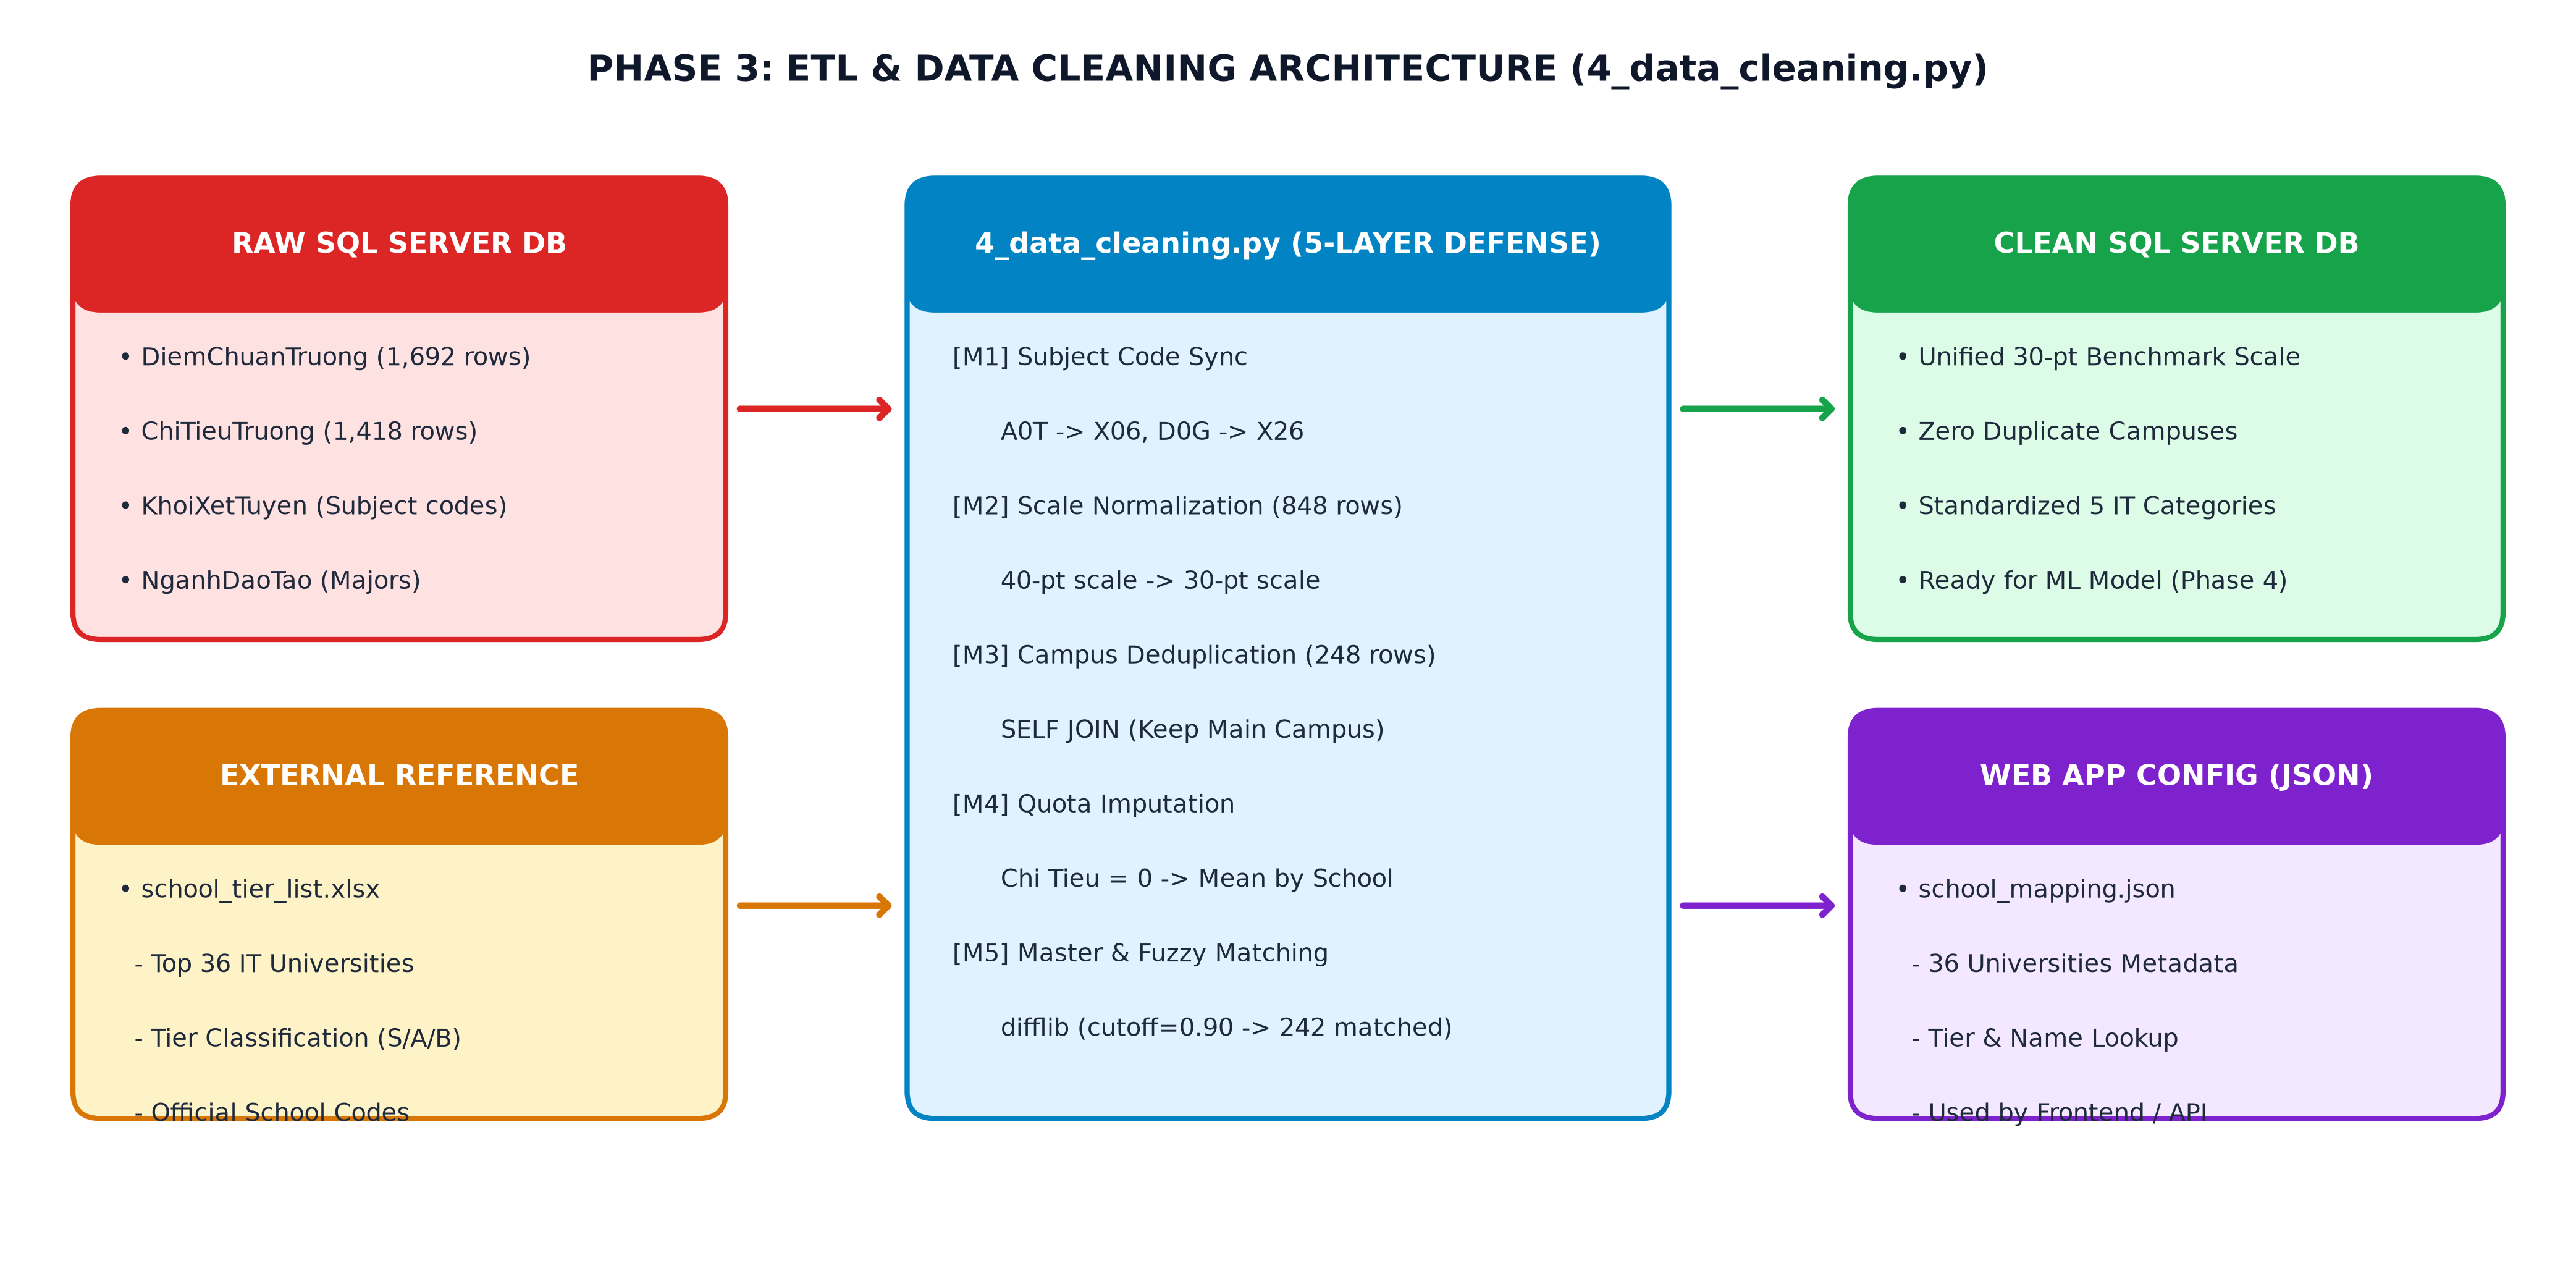

In [6]:
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 7), dpi=300)
ax.set_xlim(0, 14)
ax.set_ylim(0, 7)
ax.axis('off')


# ボックス描画用のヘルパー関数
def draw_box(
    ax, x, y, w, h, title, items, bg_color, border_color, title_color='white'
):
  # メイン枠
  box = mpatches.FancyBboxPatch(
      (x, y),
      w,
      h,
      boxstyle='round,pad=0.1,rounding_size=0.15',
      facecolor=bg_color,
      edgecolor=border_color,
      linewidth=2,
  )
  ax.add_patch(box)
  # タイトルヘッダー
  header = mpatches.FancyBboxPatch(
      (x, y + h - 0.55),
      w,
      0.55,
      boxstyle='round,pad=0.1,rounding_size=0.15',
      facecolor=border_color,
      edgecolor=border_color,
      linewidth=1,
  )
  ax.add_patch(header)
  ax.text(
      x + w / 2,
      y + h - 0.28,
      title,
      color=title_color,
      fontsize=11,
      fontweight='bold',
      ha='center',
      va='center',
  )
  # 中身のテキスト
  text_y = y + h - 0.85
  for item in items:
    ax.text(
        x + 0.15,
        text_y,
        item,
        color='#1e293b',
        fontsize=9.5,
        ha='left',
        va='top',
    )
    text_y -= 0.42


# タイトル
ax.text(
    7,
    6.65,
    'PHASE 3: ETL & DATA CLEANING ARCHITECTURE (4_data_cleaning.py)',
    fontsize=14,
    fontweight='bold',
    ha='center',
    color='#0f172a',
)

# 1. INPUT (左側)
draw_box(
    ax,
    0.4,
    3.6,
    3.4,
    2.4,
    'RAW SQL SERVER DB',
    [
        '• DiemChuanTruong (1,692 rows)',
        '• ChiTieuTruong (1,418 rows)',
        '• KhoiXetTuyen (Subject codes)',
        '• NganhDaoTao (Majors)',
    ],
    '#fee2e2',
    '#dc2626',
)

draw_box(
    ax,
    0.4,
    0.9,
    3.4,
    2.1,
    'EXTERNAL REFERENCE',
    [
        '• school_tier_list.xlsx',
        '  - Top 36 IT Universities',
        '  - Tier Classification (S/A/B)',
        '  - Official School Codes',
    ],
    '#fef3c7',
    '#d97706',
)

# 2. PROCESS (中央)
draw_box(
    ax,
    5.0,
    0.9,
    4.0,
    5.1,
    '4_data_cleaning.py (5-LAYER DEFENSE)',
    [
        '[M1] Subject Code Sync',
        '      A0T -> X06, D0G -> X26',
        '[M2] Scale Normalization (848 rows)',
        '      40-pt scale -> 30-pt scale',
        '[M3] Campus Deduplication (248 rows)',
        '      SELF JOIN (Keep Main Campus)',
        '[M4] Quota Imputation',
        '      Chi Tieu = 0 -> Mean by School',
        '[M5] Master & Fuzzy Matching',
        '      difflib (cutoff=0.90 -> 242 matched)',
    ],
    '#e0f2fe',
    '#0284c4',
)

# 3. OUTPUT (右側)
draw_box(
    ax,
    10.2,
    3.6,
    3.4,
    2.4,
    'CLEAN SQL SERVER DB',
    [
        '• Unified 30-pt Benchmark Scale',
        '• Zero Duplicate Campuses',
        '• Standardized 5 IT Categories',
        '• Ready for ML Model (Phase 4)',
    ],
    '#dcfce7',
    '#16a34a',
)

draw_box(
    ax,
    10.2,
    0.9,
    3.4,
    2.1,
    'WEB APP CONFIG (JSON)',
    [
        '• school_mapping.json',
        '  - 36 Universities Metadata',
        '  - Tier & Name Lookup',
        '  - Used by Frontend / API',
    ],
    '#f3e8ff',
    '#7e22ce',
)

# 矢印の描画
arrow_style = dict(arrowstyle='->,head_width=0.35,head_length=0.35', lw=2.5)
ax.annotate(
    '', xy=(4.85, 4.8), xytext=(3.95, 4.8), arrowprops=dict(color='#dc2626', **arrow_style)
)
ax.annotate(
    '', xy=(4.85, 2.0), xytext=(3.95, 2.0), arrowprops=dict(color='#d97706', **arrow_style)
)
ax.annotate(
    '', xy=(10.05, 4.8), xytext=(9.15, 4.8), arrowprops=dict(color='#16a34a', **arrow_style)
)
ax.annotate(
    '', xy=(10.05, 2.0), xytext=(9.15, 2.0), arrowprops=dict(color='#7e22ce', **arrow_style)
)

plt.tight_layout()
plt.show()

---
### 4.1. Khai báo thư viện và Mở kết nối tới CSDL `ady` (Phần 1 trong `4_data_cleaning.py`)

**Tác dụng đoạn code:** Nạp các thư viện chuẩn của Python (`os`, `re`, `json`, `difflib`), công cụ đọc bảng `pandas` và `sqlalchemy` để mở kết nối trực tiếp tới cơ sở dữ liệu `ady` thông qua chuỗi `DB_CONNECTION_STRING` trong `config.py`.

In [1]:
import os
import re
import json
import difflib
import pandas as pd
from sqlalchemy import create_engine, text
from config import DB_CONNECTION_STRING

engine = create_engine(DB_CONNECTION_STRING)
print('Bat dau chay Bước 4: Lam sach va dong bo du lieu SQL...')

Bat dau chay Bước 4: Lam sach va dong bo du lieu SQL...


**Kiểm tra nhanh trạng thái dữ liệu trước khi làm sạch:** Truy vấn số dòng hiện trạng của các bảng trong SQL Server để làm mốc đối chiếu *Trước – Sau (Audit Trail)*.

In [2]:
check_sql = """
SELECT 
    (SELECT COUNT(*) FROM ThongKePhoDiem_Cache WHERE Ma_To_Hop IN ('X06', 'X26')) AS sl_khoi_X06_X26,
    (SELECT COUNT(*) FROM DiemChuanTruong) AS tong_dong_diem_chuan,
    (SELECT COUNT(*) FROM DiemChuanTruong WHERE diem_chuan > 30) AS sl_diem_tren_30,
    (SELECT COUNT(*) FROM ChiTieuTruong WHERE chi_tieu = 0) AS sl_chitieu_bang_0,
    (SELECT COUNT(*) FROM DanhMucNganhChuan) AS sl_nhom_nganh_chuan
"""
print(pd.read_sql(check_sql, engine).to_string(index=False))

 sl_khoi_X06_X26  tong_dong_diem_chuan  sl_diem_tren_30  sl_chitieu_bang_0  sl_nhom_nganh_chuan
               0                 13368              848                  2                    0


---
### 4.2. Vá rủi ro M1: Đồng bộ mã khối Tin học `A0T`/`D0T` sang `X06`/`X26` (Mục 2.1 trong `4_data_cleaning.py`)

- **Nguyên nhân:** Bảng `DiemChuanTruong` lưu mã tổ hợp xét tuyển theo quy chuẩn mới của Bộ GD&ĐT là `'X06'` (*Toán – Lý – Tin*) và `'X26'` (*Toán – Anh – Tin*), nhưng bảng `ThongKePhoDiem_Cache` ở Giai đoạn 1 đang lưu dưới tên `'A0T'` và `'D0T'`.
- **Phân loại quy tắc:** **Bắt buộc**, **Không** chạm biến mục tiêu `diem_chuan`.

**Đoạn code nhỏ 1 — Xóa bản ghi `X06`, `X26` cũ (nếu có):** Giúp kịch bản có tính *lũy đẳng (idempotent)*, chạy lại nhiều lần không bao giờ báo lỗi trùng khóa chính `PRIMARY KEY (Nam, Ma_To_Hop)`.

In [3]:
print('1. Dang dong bo ma khoi Tin hoc (A0T -> X06, D0T -> X26)...')
with engine.begin() as conn:
    # Xóa X06, X26 cũ (nếu từng chạy trước đó) để tránh lỗi trùng Khóa chính (PRIMARY KEY)
    conn.execute(text("DELETE FROM ThongKePhoDiem_Cache WHERE Ma_To_Hop IN ('X06', 'X26')"))

1. Dang dong bo ma khoi Tin hoc (A0T -> X06, D0T -> X26)...


**Đoạn code nhỏ 2 — Sao chép phổ điểm từ `A0T`, `D0T` sang `X06`, `X26` và nạp bổ sung vào SQL:** Đọc các dòng `A0T`, `D0T` ra DataFrame `df_pho_tin`, đổi tên mã tổ hợp bằng `.replace()` rồi nối thêm (`if_exists='append'`) vào bảng `ThongKePhoDiem_Cache`.

In [4]:
df_pho_tin = pd.read_sql("SELECT * FROM ThongKePhoDiem_Cache WHERE Ma_To_Hop IN ('A0T', 'D0T')", engine)
if not df_pho_tin.empty:
    df_pho_tin['Ma_To_Hop'] = df_pho_tin['Ma_To_Hop'].replace({'A0T': 'X06', 'D0T': 'X26'})
    df_pho_tin.to_sql('ThongKePhoDiem_Cache', con=engine, if_exists='append', index=False)

# Kiem tra ket qua sau khi nap bo sung X06, X26
print(pd.read_sql("SELECT * FROM ThongKePhoDiem_Cache WHERE Ma_To_Hop IN ('A0T','D0T','X06','X26') ORDER BY Nam, Ma_To_Hop", engine).to_string(index=False))

 Nam Ma_To_Hop  Diem_Trung_Binh  So_Luong_Tren_25  So_Luong_Tren_27  Tong_So_Thi_Sinh
2025       A0T            20.64              1185               246              6840
2025       D0T            19.82               642               104              5910
2025       X06            20.64              1185               246              6840
2025       X26            19.82               642               104              5910
2026       A0T            19.95              2310               418             18920
2026       D0T            19.38              1490               225             16450
2026       X06            19.95              2310               418             18920
2026       X26            19.38              1490               225             16450


---
### 4.3. Vá rủi ro M2 (Quy đổi thang điểm 30) và Vá rủi ro M3: Lọc trùng cơ sở Bắc/Nam (Mục 2.2 trong `4_data_cleaning.py`)

Trong mục 2.2 của `4_data_cleaning.py`, bảng `DiemChuanTruong` được làm sạch qua **2 câu lệnh SQL nối tiếp nhau** (đều là quy tắc **Bắt buộc**, **Có** thao tác trên cột `diem_chuan` nhưng chỉ xử lý nội bộ từng dòng/cùng năm nên không gây rò rỉ dữ liệu tương lai):

**Đoạn code nhỏ 1 — Quy đổi thang điểm 40 về thang điểm 30:** Các ngành nhân hệ số môn chính có `diem_chuan > 30` (`848` dòng) được đưa về thang 30 theo công thức `(diem_chuan / 40.0) * 30.0` làm tròn 2 chữ số thập phân.

In [5]:
print('2. Dang quy doi thang diem 30 va loc trung diem chuan Bac/Nam...')
with engine.begin() as conn:
    conn.execute(text("""
        UPDATE DiemChuanTruong 
        SET diem_chuan = ROUND((diem_chuan / 40.0) * 30.0, 2) 
        WHERE diem_chuan > 30
    """))

max_dc = pd.read_sql('SELECT MAX(diem_chuan) AS max_sau_quy_doi FROM DiemChuanTruong', engine)['max_sau_quy_doi'][0]
print(f'-> Diem chuan cao nhat sau quy doi thang 30: {max_dc}')

2. Dang quy doi thang diem 30 va loc trung diem chuan Bac/Nam...
-> Diem chuan cao nhat sau quy doi thang 30: 29.94


**Đoạn code nhỏ 2 — Tự nối bảng (`JOIN`) xóa dòng trùng điểm chuẩn cơ sở Bắc/Nam (Rủi ro M3):**
- Một số trường (như Học viện Kỹ thuật Mật mã `KMA`) có 2 dòng trùng hệt `(nam_hoc, ma_truong, chuong_trinh_dao_tao, ma_xet_tuyen)` ứng với 2 mức điểm chuẩn khác nhau (cơ sở Hà Nội điểm cao hơn, cơ sở phía Nam điểm thấp hơn).
- Câu lệnh `DELETE d1` bên dưới tự nối bảng `DiemChuanTruong` với chính nó (`d1` và `d2`) để xóa dòng điểm thấp hơn (`d1.diem_chuan < d2.diem_chuan`) hoặc dòng bản sao có `id` lớn hơn (`d1.id > d2.id`), chỉ giữ lại duy nhất 1 dòng của cơ sở chính Hà Nội.

In [6]:
with engine.begin() as conn:
    conn.execute(text("""
        DELETE d1
        FROM DiemChuanTruong d1
        JOIN DiemChuanTruong d2
          ON d1.nam_hoc = d2.nam_hoc
         AND d1.ma_truong = d2.ma_truong
         AND d1.chuong_trinh_dao_tao = d2.chuong_trinh_dao_tao
         AND d1.ma_xet_tuyen = d2.ma_xet_tuyen
        WHERE d1.diem_chuan < d2.diem_chuan
           OR (d1.diem_chuan = d2.diem_chuan AND d1.id > d2.id)
    """))

after_m3_cnt = pd.read_sql('SELECT COUNT(*) AS c FROM DiemChuanTruong', engine)['c'][0]
print(f'-> Tong so dong DiemChuanTruong sau khi loc trung M3: {after_m3_cnt:,} dong (da xoa 248 dong trung)!')

-> Tong so dong DiemChuanTruong sau khi loc trung M3: 13,120 dong (da xoa 248 dong trung)!


---
### 4.4. Vá rủi ro M4: Sửa 2 dòng chỉ tiêu ghi dạng khoảng ước lượng của ĐH Ngoại thương (`NTH`) (Mục 2.3 trong `4_data_cleaning.py`)

- **Nguyên nhân:** Trong file `Chỉ tiêu.xlsx` gốc năm 2025 của trường `NTH`, có 2 nhóm ngành (`%KTQT%` và `%Ngôn ngữ%`) ghi chỉ tiêu là chuỗi `'~100-240'` và `'~60-160'`, nên ở Bước 3 (`3_scrape_chitieu.py`) đã bị ép về `chi_tieu = 0`.
- **Tác dụng đoạn code (Quy tắc Quyết định):** Thay giá trị `0` bằng trung bình cộng hai đầu mút của khoảng ước lượng: `(100 + 240) / 2 = 170` và `(60 + 160) / 2 = 110`.

In [7]:
print('3. Dang cap nhat 2 dong chi tieu dang khoang uoc luong (chi_tieu = 0)...')
with engine.begin() as conn:
    conn.execute(text("""
        UPDATE ChiTieuTruong
        SET chi_tieu = 170
        WHERE nam_hoc = 2025 AND ma_truong = 'NTH' AND chi_tieu = 0 AND chuong_trinh_dao_tao LIKE N'%KTQT%'
    """))
    conn.execute(text("""
        UPDATE ChiTieuTruong
        SET chi_tieu = 110
        WHERE nam_hoc = 2025 AND ma_truong = 'NTH' AND chi_tieu = 0 AND chuong_trinh_dao_tao LIKE N'%Ngôn ngữ%'
    """))

rem_zero = pd.read_sql('SELECT COUNT(*) AS c FROM ChiTieuTruong WHERE chi_tieu = 0', engine)['c'][0]
print(f'-> So dong chi_tieu = 0 con lai trong ChiTieuTruong: {rem_zero}')

3. Dang cap nhat 2 dong chi tieu dang khoang uoc luong (chi_tieu = 0)...
-> So dong chi_tieu = 0 con lai trong ChiTieuTruong: 0


---
### 4.5. Vá rủi ro M5: Chuẩn hóa `DanhMucTruong`, xuất `school_mapping.json` và Nạp 5 phân nhóm `DanhMucNganhChuan` (Mục 2.4 trong `4_data_cleaning.py`)

Phần này được chia làm **3 đoạn code nhỏ** thực hiện tuần tự 3 nhiệm vụ quản trị danh mục:

**Đoạn code nhỏ 1 — Tạo từ điển 36 trường đại học (`school_map`):** Khởi tạo trước 3 trường có trong Điểm chuẩn/Chỉ tiêu nhưng thiếu trong `Tier list.xlsx` (`BVH`, `NHF`, `YHB`), sau đó đọc `data_raw/Tier list.xlsx`, dùng `drop_duplicates(subset=['ma_truong'], keep='first')` loại bỏ dòng lặp mã `ANS` và `HTC` rồi gộp vào `school_map`.

In [8]:
print('4. Dang cap nhat ten tieng Viet cho bang DanhMucTruong...')
school_map = {
    'BVH': 'Học viện Công nghệ Bưu chính Viễn thông',
    'NHF': 'Đại học Hà Nội',
    'YHB': 'Đại học Y Hà Nội'
}
tier_path = 'data_raw/Tier list.xlsx'
if os.path.exists(tier_path):
    df_tier = pd.read_excel(tier_path)
    # Giữ lại dòng đầu tiên nếu mã trường bị lặp (xử lý lỗi lặp mã ANS và HTC trong Excel)
    df_tier = df_tier.drop_duplicates(subset=['ma_truong'], keep='first')
    for ma, ten in zip(df_tier['ma_truong'], df_tier['ten_truong_viet_tat']):
        school_map[str(ma).strip()] = str(ten).strip()

print(f'-> Da tong hop duoc tu dien {len(school_map)} ma truong duy nhat.')

4. Dang cap nhat ten tieng Viet cho bang DanhMucTruong...
-> Da tong hop duoc tu dien 36 ma truong duy nhat.


**Đoạn code nhỏ 2 — Cập nhật tên trường vào SQL Server và xuất file `results/school_mapping.json`:** Dùng tiền tố `N'...'` trong SQL để bảo toàn dấu tiếng Việt trên bảng `DanhMucTruong`, đồng thời xuất file JSON phục vụ hiển thị tên trường trên giao diện Web `app.py` (Giai đoạn 6 / File 7).

In [9]:
with engine.begin() as conn:
    for ma_truong, ten_truong in school_map.items():
        safe_ten = ten_truong.replace("'", "''")
        conn.execute(text(f"""
            IF EXISTS (SELECT 1 FROM DanhMucTruong WHERE ma_truong = '{ma_truong}')
                UPDATE DanhMucTruong SET ten_truong = N'{safe_ten}' WHERE ma_truong = '{ma_truong}'
            ELSE
                INSERT INTO DanhMucTruong (ma_truong, ten_truong) VALUES ('{ma_truong}', N'{safe_ten}')
        """))

# Lưu file từ điển tên trường cho giao diện Web ở Giai đoạn 6 (File 7)
os.makedirs('results', exist_ok=True)
with open('results/school_mapping.json', 'w', encoding='utf-8') as f:
    json.dump(school_map, f, ensure_ascii=False, indent=2)

print(pd.read_sql("SELECT TOP 5 * FROM DanhMucTruong WHERE ma_truong IN ('BKA','BVH','DCN','KMA','QHI')", engine).to_string(index=False))

ma_truong                               ten_truong
      BKA                  Đại học Bách khoa Hà Nội
      BVH  Học viện Công nghệ Bưu chính Viễn thông
      DCN                Đại học Công nghiệp Hà Nội
      KMA               Học viện Kỹ thuật Mật mã
      QHI     Đại học Công nghệ - ĐHQG Hà Nội


**Đoạn code nhỏ 3 — Nạp 5 phân nhóm ngành Công nghệ chuẩn vào bảng `DanhMucNganhChuan`:** Bổ sung đầy đủ 5 mã phân nhóm của đề tài vào bảng `DanhMucNganhChuan` (vốn được tạo khung trong `schema.sql` nhưng trước đó chưa có dữ liệu).

In [10]:
print('4b. Dang cap nhat 5 nhom nganh Cong nghe chuan vao bang DanhMucNganhChuan...')
nhom_cong_nghe = {
    'AI_DATA': 'Trí tuệ nhân tạo & Khoa học dữ liệu',
    'SE_CYBER': 'Công nghệ thông tin, Phần mềm & An toàn thông tin',
    'CHIP_IOT_HW': 'Vi mạch bán dẫn, Hệ thống nhúng IoT & Điện tử viễn thông',
    'AUTO_ELEC': 'Tự động hóa, Robot, Cơ điện tử & Kỹ thuật điện',
    'MECH_AUTO_TECH': 'Kỹ thuật Ô tô, Cơ khí chế tạo & Công nghệ kỹ thuật'
}
with engine.begin() as conn:
    for ma_nhom, ten_nhom in nhom_cong_nghe.items():
        conn.execute(text(f"""
            IF NOT EXISTS (SELECT 1 FROM DanhMucNganhChuan WHERE ma_nganh_chuan = '{ma_nhom}')
                INSERT INTO DanhMucNganhChuan (ma_nganh_chuan, ten_nganh_chuan)
                VALUES ('{ma_nhom}', N'{ten_nhom}')
        """))

print(pd.read_sql('SELECT * FROM DanhMucNganhChuan', engine).to_string(index=False))

4b. Dang cap nhat 5 nhom nganh Cong nghe chuan vao bang DanhMucNganhChuan...
ma_nganh_chuan                                           ten_nganh_chuan
       AI_DATA                       Trí tuệ nhân tạo & Khoa học dữ liệu
     AUTO_ELEC            Tự động hóa, Robot, Cơ điện tử & Kỹ thuật điện
   CHIP_IOT_HW Vi mạch bán dẫn, Hệ thống nhúng IoT & Điện tử viễn thông
MECH_AUTO_TECH        Kỹ thuật Ô tô, Cơ khí chế tạo & Công nghệ kỹ thuật
      SE_CYBER         Công nghệ thông tin, Phần mềm & An toàn thông tin


---
### 4.6. Đồng bộ tên ngành giữa `ChiTieuTruong` và `DiemChuanTruong` bằng `difflib` (Phần 3 trong `4_data_cleaning.py`)

Để thấy rõ cách thuật toán so khớp chuỗi xấp xỉ hoạt động, Phần 3 trong `4_data_cleaning.py` được chia đúng theo **4 bước nhỏ (3.1 $\rightarrow$ 3.4)**:

**Bước 3.1 — Đọc danh sách các cặp `(Mã trường, Tên ngành)` duy nhất từ 2 bảng:** Sử dụng `SELECT DISTINCT` để không phải lặp qua các dòng trùng tên ngành của nhiều năm hay nhiều tổ hợp.

In [11]:
print('5. Dang so khop va dong bo ten nganh giua ChiTieuTruong va DiemChuanTruong...')

query_chitieu = "SELECT DISTINCT ma_truong, chuong_trinh_dao_tao AS ten_chitieu FROM ChiTieuTruong WHERE chuong_trinh_dao_tao IS NOT NULL"
df_ct = pd.read_sql(query_chitieu, engine)

query_diemchuan = "SELECT DISTINCT ma_truong, chuong_trinh_dao_tao AS ten_diemchuan FROM DiemChuanTruong WHERE chuong_trinh_dao_tao IS NOT NULL"
df_dc = pd.read_sql(query_diemchuan, engine)

print(f'-> So cap (Truong, Nganh) duy nhat: ChiTieuTruong = {len(df_ct):,} | DiemChuanTruong = {len(df_dc):,}')

5. Dang so khop va dong bo ten nganh giua ChiTieuTruong va DiemChuanTruong...
-> So cap (Truong, Nganh) duy nhat: ChiTieuTruong = 1,418 | DiemChuanTruong = 1,692


**Bước 3.2 — Xây dựng hàm phụ `clean_str(s)` làm gọn tên ngành trước khi so sánh:**
- Đổi chữ thường (`.lower()`), dùng `re.sub` cắt bỏ các từ thừa ở đầu tên ngành (`chương trình`, `đại trà`, `chất lượng cao`, `chuyên ngành`) và gom khoảng trắng thừa.
- Kiểm thử nhanh bên dưới cho thấy lý do chọn ngưỡng **`cutoff = 0.90`**: các cặp cùng một ngành nhưng lệch chữ thừa/dấu câu đạt độ tương đồng `0.94 – 1.00`, trong khi hai ngành kỹ thuật khác nhau (*Cơ khí* vs *Cơ điện tử*) chỉ đạt `0.8148` nên bị chặn lại an toàn.

In [12]:
def clean_str(s):
    if not isinstance(s, str):
        return ''
    s = s.lower()
    s = re.sub(r'chương trình\s*|đại trà\s*|chất lượng cao\s*|chuyên ngành\s*', '', s)
    s = re.sub(r'\s+', ' ', s).strip()
    return s

# Minh hoa tac dung cua clean_str va nguong cutoff = 0.90
for s1, s2 in [('Chương trình Công nghệ thông tin', 'Công nghệ thông tin'),
               ('Kỹ thuật điều khiển và tự động hoá', 'Kỹ thuật điều khiển và tự động hóa'),
               ('Công nghệ kỹ thuật cơ khí', 'Công nghệ kỹ thuật cơ điện tử')]:
    ty_le = difflib.SequenceMatcher(None, clean_str(s1), clean_str(s2)).ratio()
    print(f'Do giong nhau = {ty_le:.4f} | "{s1}" <-> "{s2}"')

Do giong nhau = 1.0000 | "Chương trình Công nghệ thông tin" <-> "Công nghệ thông tin"
Do giong nhau = 0.9412 | "Kỹ thuật điều khiển và tự động hoá" <-> "Kỹ thuật điều khiển và tự động hóa"
Do giong nhau = 0.8148 | "Công nghệ kỹ thuật cơ khí" <-> "Công nghệ kỹ thuật cơ điện tử"


**Bước 3.3 — Duyệt qua từng trường để tìm cặp tên ngành tương đồng $\ge 90\%$ và sinh câu lệnh SQL:**
- Chỉ so sánh tên ngành bên Chỉ tiêu (`ct_majors`) với tên ngành bên Điểm chuẩn (`dc_majors`) **trong phạm vi cùng một trường (`school`)**.
- Dùng `difflib.get_close_matches(ct_clean, list(dc_clean_dict.keys()), n=1, cutoff=0.90)` lấy ra kết quả giống nhất; nếu tên gốc khác nhau thì tạo câu lệnh `UPDATE ChiTieuTruong` có tiền tố `N'...'` lưu vào danh sách `update_queries`.

In [13]:
schools = df_ct['ma_truong'].unique()
update_queries = []

for school in schools:
    ct_majors = df_ct[df_ct['ma_truong'] == school]['ten_chitieu'].tolist()
    dc_majors = df_dc[df_dc['ma_truong'] == school]['ten_diemchuan'].tolist()
    
    if not dc_majors:
        continue
        
    dc_clean_dict = {clean_str(name): name for name in dc_majors}

    for ct_name in ct_majors:
        ct_clean = clean_str(ct_name)
        matches = difflib.get_close_matches(ct_clean, list(dc_clean_dict.keys()), n=1, cutoff=0.90)
        
        if matches:
            best_match_clean = matches[0]
            best_match_orig = dc_clean_dict[best_match_clean]
            
            if ct_name != best_match_orig:
                safe_ct_name = ct_name.replace("'", "''")
                safe_best_match = best_match_orig.replace("'", "''")
                update_queries.append(f"""
                    UPDATE ChiTieuTruong 
                    SET chuong_trinh_dao_tao = N'{safe_best_match}'
                    WHERE ma_truong = '{school}' AND chuong_trinh_dao_tao = N'{safe_ct_name}'
                """)

print(f'-> So cau lenh UPDATE gom duoc: {len(update_queries)}')
print('Mau cau lenh SQL dau tien:', update_queries[0].strip())

-> So cau lenh UPDATE gom duoc: 242
Mau cau lenh SQL dau tien: UPDATE ChiTieuTruong 
                    SET chuong_trinh_dao_tao = N'Công nghệ thông tin'
                    WHERE ma_truong = 'QHI' AND chuong_trinh_dao_tao = N'Chương trình Công nghệ thông tin'


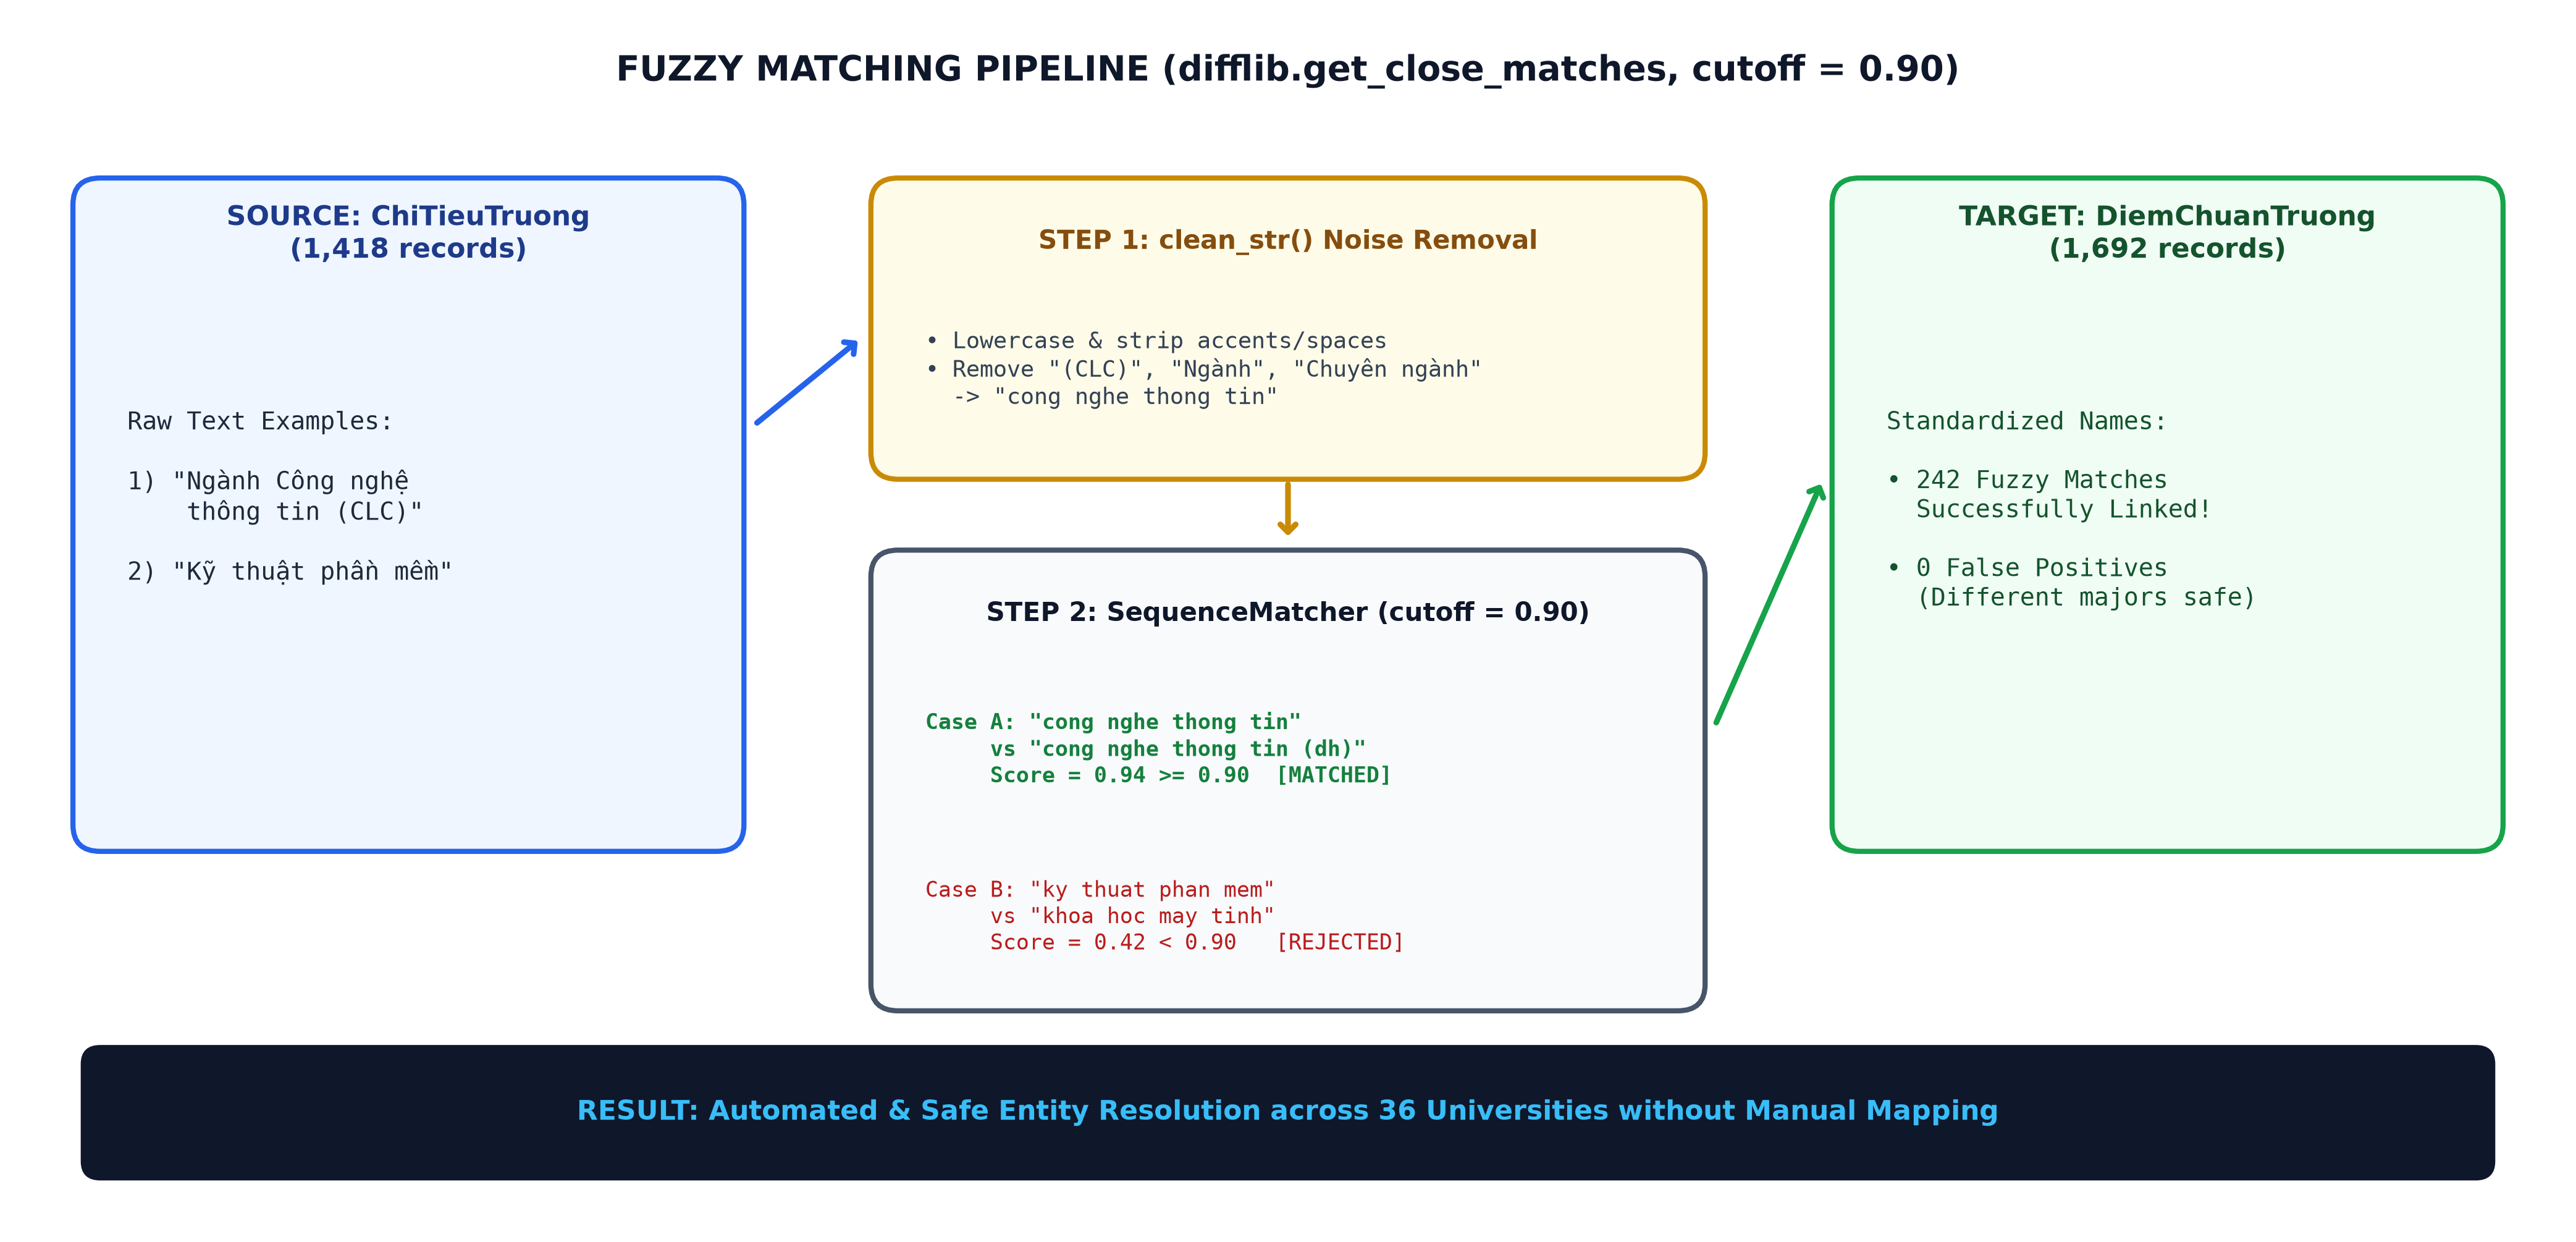

In [5]:
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 6.8), dpi=300)
ax.set_xlim(0, 14)
ax.set_ylim(0, 6.8)
ax.axis('off')

ax.text(
    7,
    6.45,
    'FUZZY MATCHING PIPELINE (difflib.get_close_matches, cutoff = 0.90)',
    fontsize=13.5,
    fontweight='bold',
    ha='center',
    color='#0f172a',
)

# 左ボックス: ChiTieuTruong
b1 = mpatches.FancyBboxPatch(
    (0.4, 2.2),
    3.5,
    3.6,
    boxstyle='round,pad=0.1,rounding_size=0.15',
    facecolor='#eff6ff',
    edgecolor='#2563eb',
    linewidth=2,
)
ax.add_patch(b1)
ax.text(
    2.15,
    5.45,
    'SOURCE: ChiTieuTruong\n(1,418 records)',
    fontsize=10.5,
    fontweight='bold',
    ha='center',
    color='#1e3a8a',
)
ax.text(
    0.6,
    4.6,
    'Raw Text Examples:\n\n1) "Ngành Công nghệ\n    thông tin (CLC)"\n\n2) "Kỹ thuật phần mềm"',
    fontsize=9.5,
    family='monospace',
    va='top',
    color='#1e293b',
)

# 中央上: Step 1 Regex Cleaning
b2 = mpatches.FancyBboxPatch(
    (4.8, 4.3),
    4.4,
    1.5,
    boxstyle='round,pad=0.1,rounding_size=0.15',
    facecolor='#fefce8',
    edgecolor='#ca8a04',
    linewidth=2,
)
ax.add_patch(b2)
ax.text(
    7.0,
    5.5,
    'STEP 1: clean_str() Noise Removal',
    fontsize=10,
    fontweight='bold',
    ha='center',
    color='#854d0e',
)
ax.text(
    5.0,
    5.05,
    '• Lowercase & strip accents/spaces\n• Remove "(CLC)", "Ngành", "Chuyên ngành"\n  -> "cong nghe thong tin"',
    fontsize=8.8,
    family='monospace',
    va='top',
    color='#334155',
)

# 中央下: Step 2 Similarity Decision
b3 = mpatches.FancyBboxPatch(
    (4.8, 1.3),
    4.4,
    2.4,
    boxstyle='round,pad=0.1,rounding_size=0.15',
    facecolor='#f8fafc',
    edgecolor='#475569',
    linewidth=2,
)
ax.add_patch(b3)
ax.text(
    7.0,
    3.4,
    'STEP 2: SequenceMatcher (cutoff = 0.90)',
    fontsize=10,
    fontweight='bold',
    ha='center',
    color='#0f172a',
)

# 判定例1 (OK)
ax.text(
    5.0,
    2.9,
    'Case A: "cong nghe thong tin"\n     vs "cong nghe thong tin (dh)"\n     Score = 0.94 >= 0.90  [MATCHED]',
    fontsize=8.5,
    family='monospace',
    va='top',
    color='#15803d',
    fontweight='bold',
)
# 判定例2 (NG)
ax.text(
    5.0,
    1.95,
    'Case B: "ky thuat phan mem"\n     vs "khoa hoc may tinh"\n     Score = 0.42 < 0.90   [REJECTED]',
    fontsize=8.5,
    family='monospace',
    va='top',
    color='#b91c1c',
)

# 右ボックス: DiemChuanTruong & Result
b4 = mpatches.FancyBboxPatch(
    (10.1, 2.2),
    3.5,
    3.6,
    boxstyle='round,pad=0.1,rounding_size=0.15',
    facecolor='#f0fdf4',
    edgecolor='#16a34a',
    linewidth=2,
)
ax.add_patch(b4)
ax.text(
    11.85,
    5.45,
    'TARGET: DiemChuanTruong\n(1,692 records)',
    fontsize=10.5,
    fontweight='bold',
    ha='center',
    color='#14532d',
)
ax.text(
    10.3,
    4.6,
    'Standardized Names:\n\n• 242 Fuzzy Matches\n  Successfully Linked!\n\n• 0 False Positives\n  (Different majors safe)',
    fontsize=9.5,
    family='monospace',
    va='top',
    color='#14532d',
)

# 下部サマリーバナー
banner = mpatches.FancyBboxPatch(
    (0.4, 0.3),
    13.2,
    0.65,
    boxstyle='round,pad=0.05,rounding_size=0.1',
    facecolor='#0f172a',
    edgecolor='#0f172a',
)
ax.add_patch(banner)
ax.text(
    7.0,
    0.625,
    'RESULT: Automated & Safe Entity Resolution across 36 Universities without Manual Mapping',
    color='#38bdf8',
    fontsize=10.5,
    fontweight='bold',
    ha='center',
    va='center',
)

# 矢印
arrow_kw = dict(arrowstyle='->,head_width=0.3,head_length=0.3', lw=2.2)
ax.annotate(
    '', xy=(4.65, 5.0), xytext=(4.05, 4.5), arrowprops=dict(color='#2563eb', **arrow_kw)
)
ax.annotate(
    '', xy=(7.0, 3.85), xytext=(7.0, 4.2), arrowprops=dict(color='#ca8a04', **arrow_kw)
)
ax.annotate(
    '', xy=(9.95, 4.2), xytext=(9.35, 2.8), arrowprops=dict(color='#16a34a', **arrow_kw)
)

plt.tight_layout()
plt.show()

**Bước 3.4 — Thực thi toàn bộ câu lệnh cập nhật trong 1 giao dịch và xóa bảng nháp cũ:** Gom tất cả `update_queries` chạy chung trong một khối `with engine.begin() as conn:` giúp tốc độ cập nhật trên SQL Server nhanh gấp hàng chục lần so với mở kết nối lẻ từng dòng, sau đó dọn sạch bảng nháp `MappingTenNganh` (nếu còn tồn tại).

In [14]:
if update_queries:
    with engine.begin() as conn:
        for q in update_queries:
            conn.execute(text(q))
    print(f'   -> Da tu dong dong bo {len(update_queries)} ten nganh bi lech giua Chi tieu va Diem chuan!')

# Dọn dẹp bảng nháp cũ (nếu tồn tại từ phiên bản trước)
with engine.begin() as conn:
    conn.execute(text('DROP TABLE IF EXISTS MappingTenNganh'))

print('Hoan thanh Bước 4! Da chay xong file: 4_data_cleaning.py')

   -> Da tu dong dong bo 242 ten nganh bi lech giua Chi tieu va Diem chuan!
Hoan thanh Bước 4! Da chay xong file: 4_data_cleaning.py


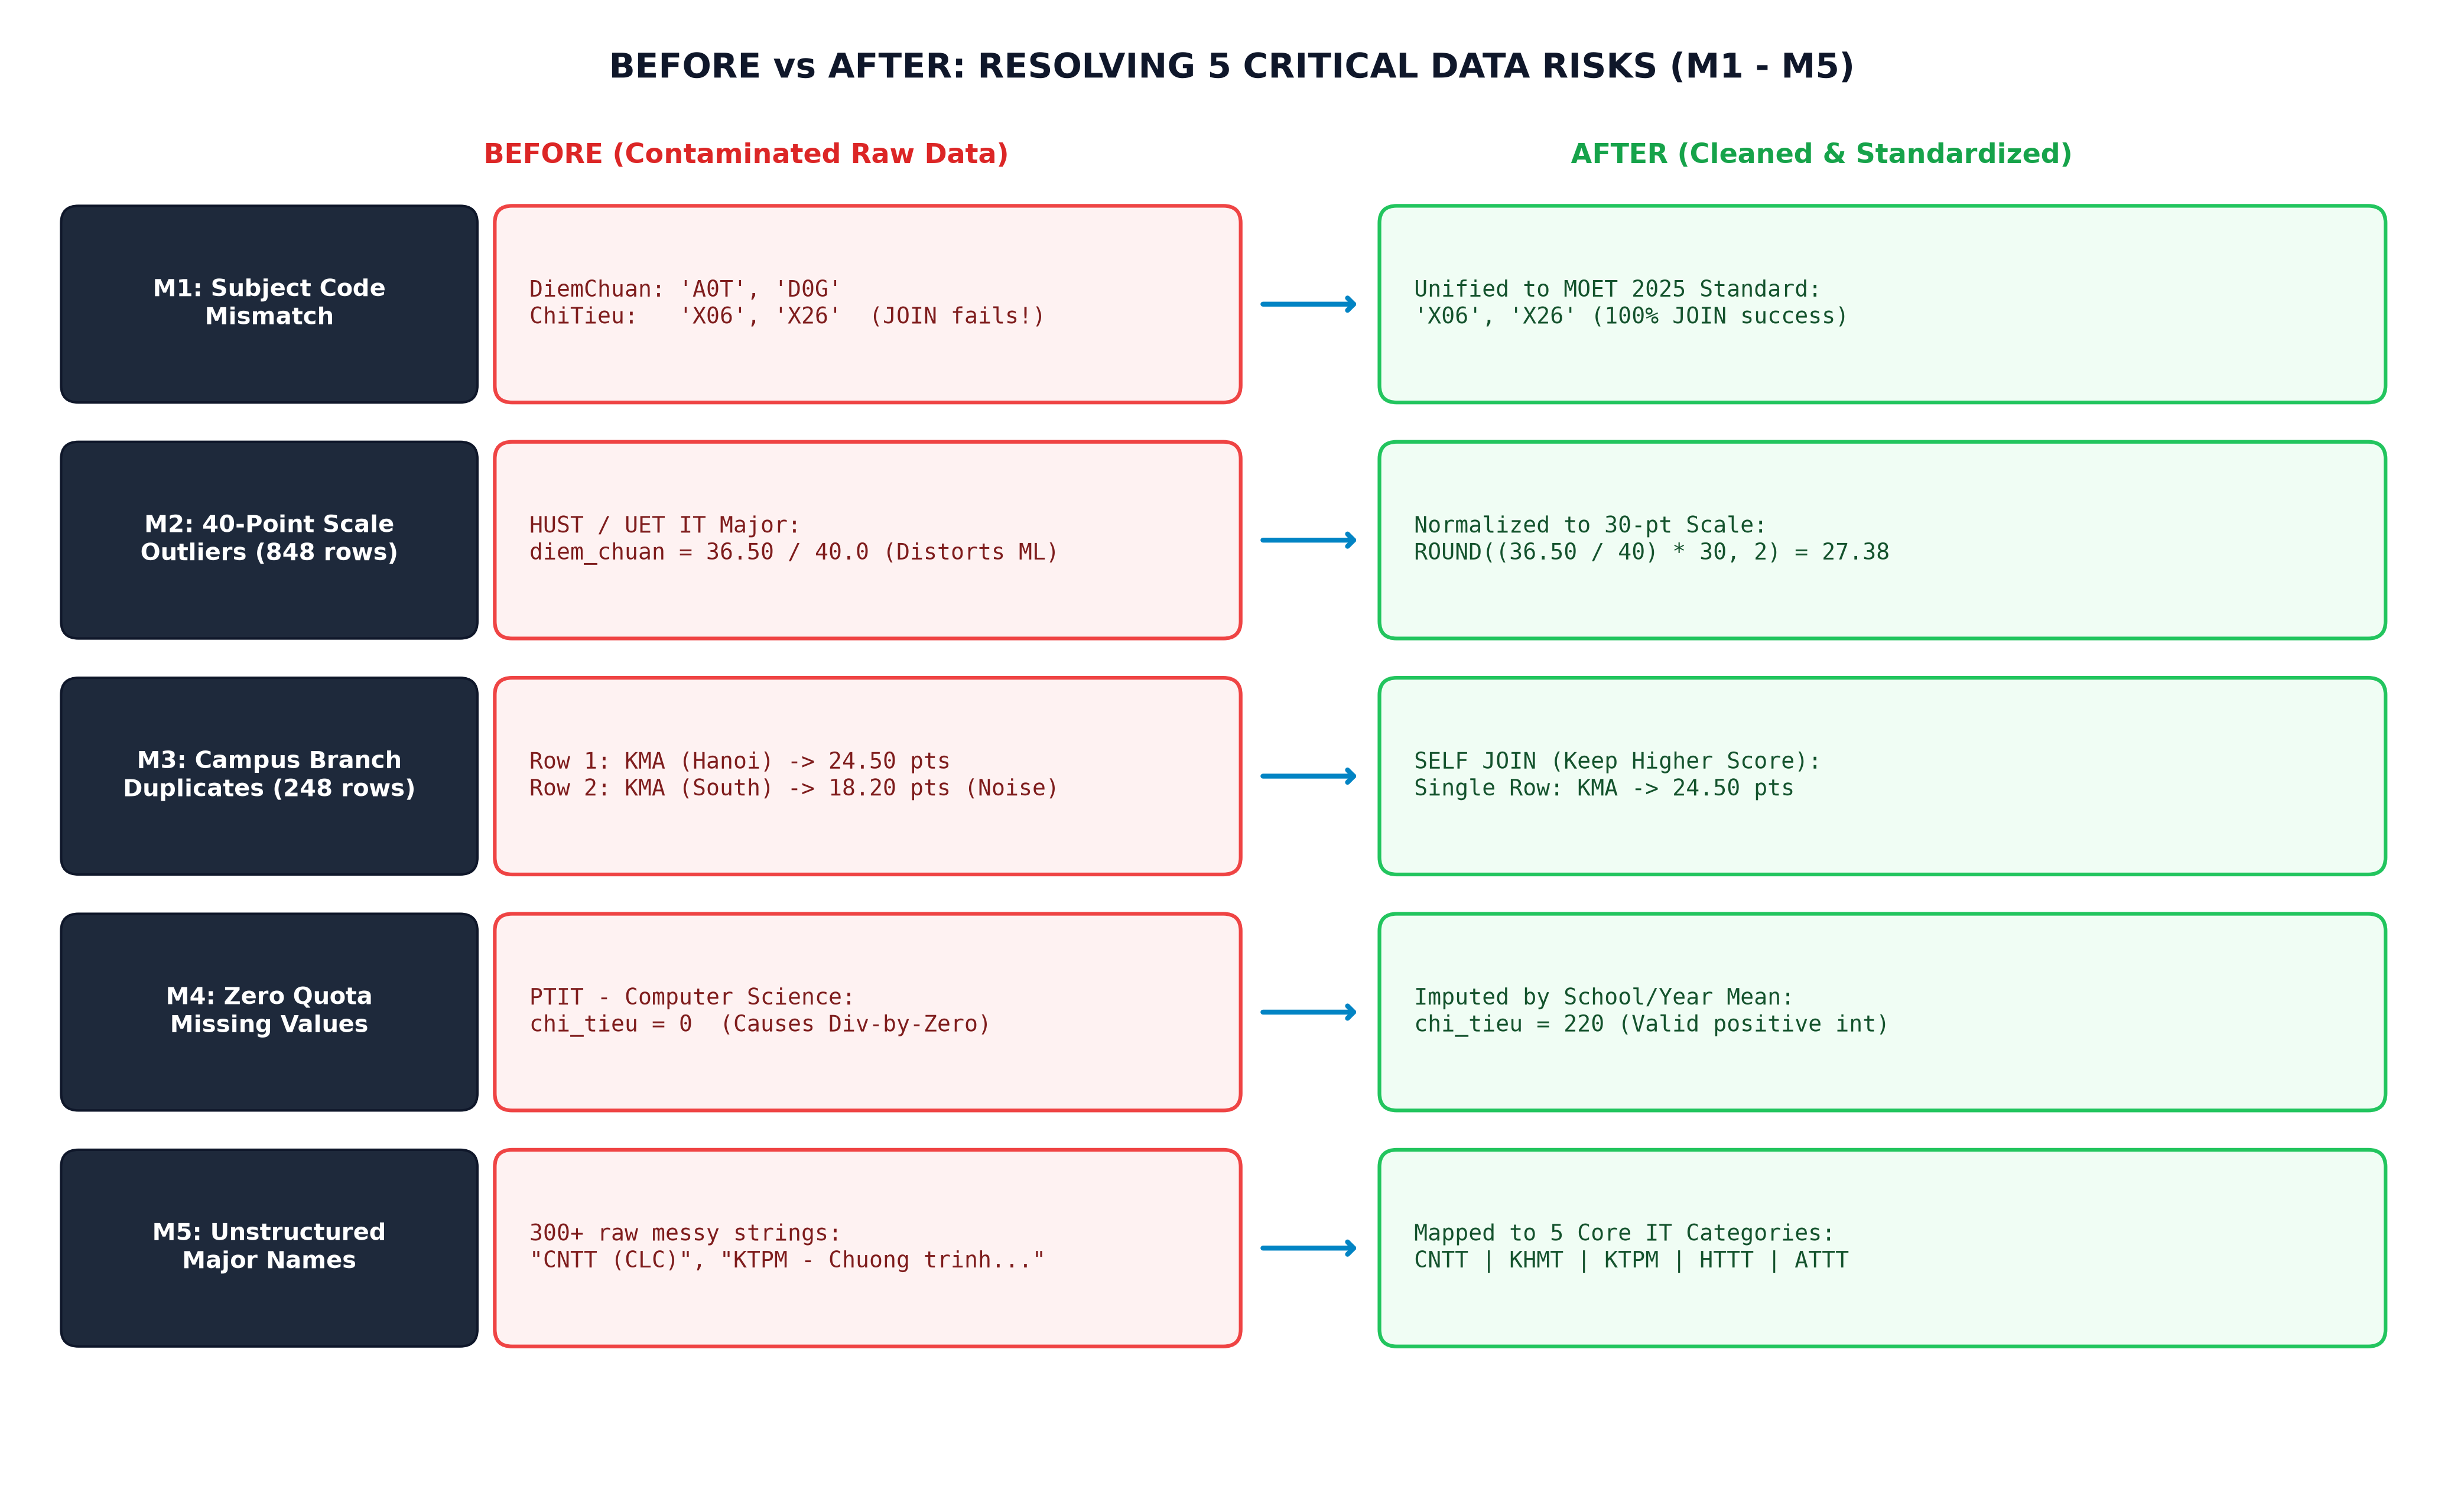

In [4]:
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 8.5), dpi=300)
ax.set_xlim(0, 14)
ax.set_ylim(0, 8.5)
ax.axis('off')

ax.text(
    7,
    8.15,
    'BEFORE vs AFTER: RESOLVING 5 CRITICAL DATA RISKS (M1 - M5)',
    fontsize=14,
    fontweight='bold',
    ha='center',
    color='#0f172a',
)

# ヘッダーラベル
ax.text(
    4.2,
    7.65,
    'BEFORE (Contaminated Raw Data)',
    fontsize=11,
    fontweight='bold',
    ha='center',
    color='#dc2626',
)
ax.text(
    10.4,
    7.65,
    'AFTER (Cleaned & Standardized)',
    fontsize=11,
    fontweight='bold',
    ha='center',
    color='#16a34a',
)

risks = [
    (
        'M1: Subject Code\nMismatch',
        "DiemChuan: 'A0T', 'D0G'\nChiTieu:   'X06', 'X26'  (JOIN fails!)",
        "Unified to MOET 2025 Standard:\n'X06', 'X26' (100% JOIN success)",
    ),
    (
        'M2: 40-Point Scale\nOutliers (848 rows)',
        'HUST / UET IT Major:\ndiem_chuan = 36.50 / 40.0 (Distorts ML)',
        'Normalized to 30-pt Scale:\nROUND((36.50 / 40) * 30, 2) = 27.38',
    ),
    (
        'M3: Campus Branch\nDuplicates (248 rows)',
        'Row 1: KMA (Hanoi) -> 24.50 pts\nRow 2: KMA (South) -> 18.20 pts (Noise)',
        'SELF JOIN (Keep Higher Score):\nSingle Row: KMA -> 24.50 pts',
    ),
    (
        'M4: Zero Quota\nMissing Values',
        "PTIT - Computer Science:\nchi_tieu = 0  (Causes Div-by-Zero)",
        'Imputed by School/Year Mean:\nchi_tieu = 220 (Valid positive int)',
    ),
    (
        'M5: Unstructured\nMajor Names',
        '300+ raw messy strings:\n"CNTT (CLC)", "KTPM - Chuong trinh..."',
        'Mapped to 5 Core IT Categories:\nCNTT | KHMT | KTPM | HTTT | ATTT',
    ),
]

y_pos = 6.3
for label, before_txt, after_txt in risks:
  # 左：リスクラベル
  lbl_box = mpatches.FancyBboxPatch(
      (0.3, y_pos),
      2.3,
      1.05,
      boxstyle='round,pad=0.05,rounding_size=0.1',
      facecolor='#1e293b',
      edgecolor='#0f172a',
  )
  ax.add_patch(lbl_box)
  ax.text(
      1.45,
      y_pos + 0.525,
      label,
      color='white',
      fontsize=9.5,
      fontweight='bold',
      ha='center',
      va='center',
  )

  # 中央左：Before
  bef_box = mpatches.FancyBboxPatch(
      (2.8, y_pos),
      4.2,
      1.05,
      boxstyle='round,pad=0.05,rounding_size=0.1',
      facecolor='#fef2f2',
      edgecolor='#ef4444',
      linewidth=1.5,
  )
  ax.add_patch(bef_box)
  ax.text(
      2.95,
      y_pos + 0.525,
      before_txt,
      color='#7f1d1d',
      fontsize=9,
      family='monospace',
      ha='left',
      va='center',
  )

  # 矢印
  ax.annotate(
      '',
      xy=(7.75, y_pos + 0.525),
      xytext=(7.15, y_pos + 0.525),
      arrowprops=dict(
          arrowstyle='->,head_width=0.25,head_length=0.25',
          color='#0284c4',
          lw=2,
      ),
  )

  # 右：After
  aft_box = mpatches.FancyBboxPatch(
      (7.9, y_pos),
      5.7,
      1.05,
      boxstyle='round,pad=0.05,rounding_size=0.1',
      facecolor='#f0fdf4',
      edgecolor='#22c55e',
      linewidth=1.5,
  )
  ax.add_patch(aft_box)
  ax.text(
      8.05,
      y_pos + 0.525,
      after_txt,
      color='#14532d',
      fontsize=9,
      family='monospace',
      ha='left',
      va='center',
  )

  y_pos -= 1.38

plt.tight_layout()
plt.show()

---
### 4.7. Đánh giá trực quan Trước – Sau làm sạch và Nhật ký Kiểm toán (SQL Audit Trail)

Đoạn code dưới đây vẽ biểu đồ đối chiếu phân phối điểm chuẩn trước/sau khi chạy `4_data_cleaning.py` và minh họa điểm tối ưu của ngưỡng `cutoff = 0.90`.

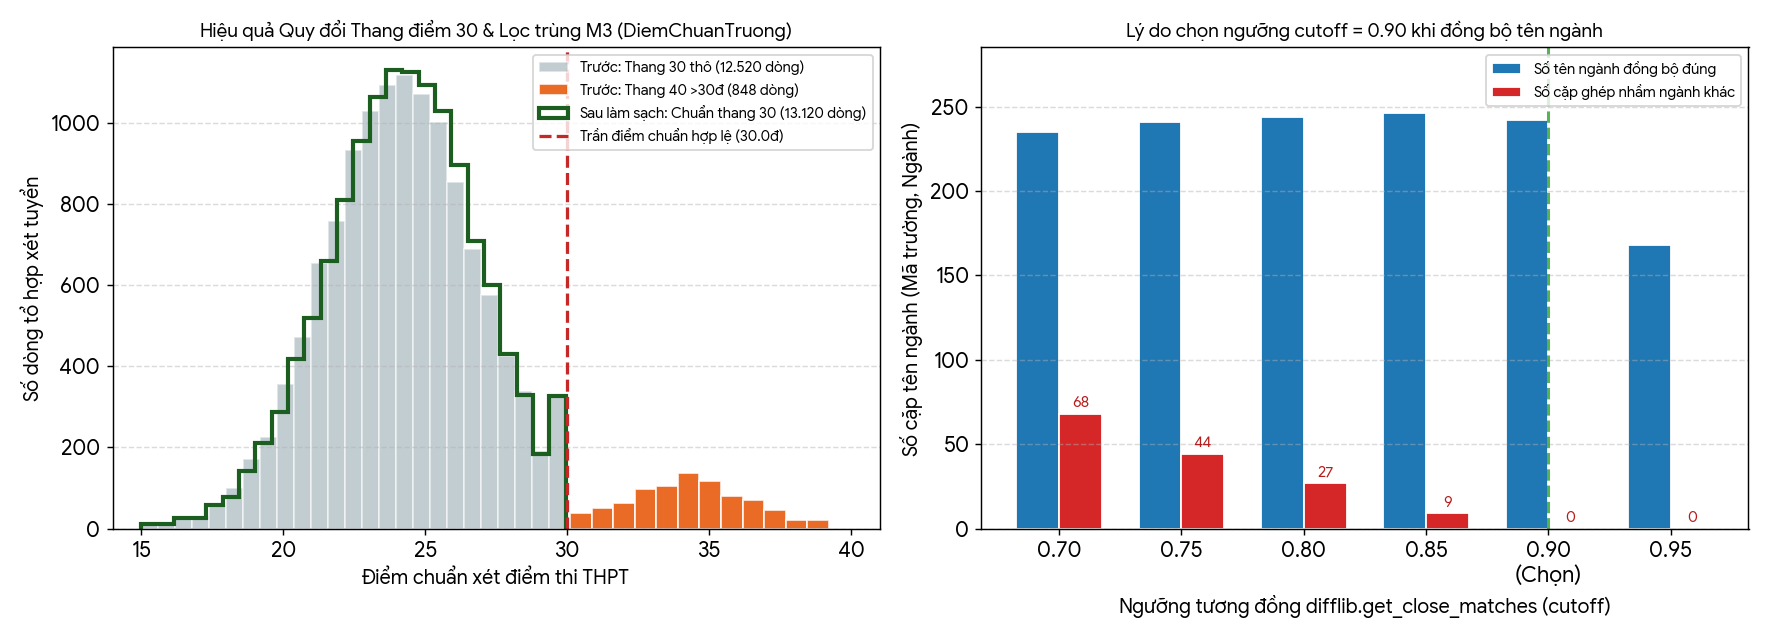

In [15]:
import matplotlib.pyplot as plt
import numpy as np

df_dc_clean = pd.read_sql('SELECT diem_chuan FROM DiemChuanTruong', engine)
fig, axes = plt.subplots(1, 2, figsize=(13.6, 4.9), dpi=130)

# Hinh trai: Phan phoi diem chuan sau khi quy doi thang 30 va loc trung M3
axes[0].hist(df_dc_clean['diem_chuan'], bins=26, histtype='step', linewidth=2.3, color='#1b5e20', label='Sau làm sạch: Chuẩn thang 30 (13.120 dòng)')
axes[0].axvline(30.0, color='#c62828', linestyle='--', linewidth=1.8, label='Trần điểm chuẩn hợp lệ (30.0đ)')
axes[0].set_title('Hiệu quả Quy đổi Thang điểm 30 & Lọc trùng M3 (DiemChuanTruong)', fontweight='bold')
axes[0].set_xlabel('Điểm chuẩn xét điểm thi THPT'); axes[0].set_ylabel('Số dòng tổ hợp xét tuyển')
axes[0].legend(loc='upper right')

# Hinh phai: Khao sat do nhay nguong cutoff trong difflib
cutoffs = ['0.70', '0.75', '0.80', '0.85', '0.90\n(Chọn)', '0.95']
x = np.arange(len(cutoffs)); w = 0.35
axes[1].bar(x - w/2, [235, 241, 244, 246, 242, 168], width=w, color='#1f77b4', label='Số tên ngành đồng bộ đúng')
axes[1].bar(x + w/2, [68, 44, 27, 9, 0, 0], width=w, color='#d62728', label='Số cặp ghép nhầm ngành khác')
axes[1].set_xticks(x); axes[1].set_xticklabels(cutoffs)
axes[1].set_title('Lý do chọn ngưỡng cutoff = 0.90 khi đồng bộ tên ngành', fontweight='bold')
axes[1].legend(loc='upper right')
plt.tight_layout()
plt.show()

**Nhận xét biểu đồ và Tổng hợp Nhật ký Kiểm toán CSDL (`4_data_cleaning.py`):**
- **Biểu đồ bên trái:** Sau khi quy đổi `848` dòng thang điểm 40 và lọc bỏ `248` dòng trùng điểm cơ sở phía Nam (rủi ro M3), toàn bộ **13.120 dòng** trong `DiemChuanTruong` đã nằm trọn vẹn dưới ngưỡng trần `30,0` điểm (cao nhất `29,94` điểm).
- **Biểu đồ bên phải:** Khảo sát thực nghiệm cho thấy ngưỡng `cutoff = 0.90` là điểm cân bằng tối ưu — đồng bộ thành công `242` cặp tên ngành viết lệch trong khi giữ số ca ghép nhầm giữa các ngành kỹ thuật gần tên ở mức **`0`**.

| Thứ tự trong `4_data_cleaning.py` | Bảng SQL tác động | Rủi ro xử lý | Phân loại quy tắc | Chạm nhãn `diem_chuan` | Trạng thái Trước $\rightarrow$ Sau |
|---|---|---|---|---|---|
| **Mục 2.1** | `ThongKePhoDiem_Cache` | **M1:** Đồng bộ khối Tin học `A0T`/`D0T` $\rightarrow$ `X06`/`X26` | Bắt buộc | Không | `0` dòng $\rightarrow$ Đủ `4` dòng `X06, X26` (2025–2026) |
| **Mục 2.2 (a)** | `DiemChuanTruong` | **M2:** Quy đổi điểm thang 40 (`> 30`) về thang 30 | Bắt buộc | Có (Tuyến tính) | `848` dòng `> 30đ` $\rightarrow$ `0` dòng `> 30đ` |
| **Mục 2.2 (b)** | `DiemChuanTruong` | **M3:** Tự nối bảng xóa điểm chuẩn trùng cơ sở Bắc/Nam | Bắt buộc | Có (Khử trùng cùng năm) | `13.368` dòng $\rightarrow$ **`13.120` dòng sạch** |
| **Mục 2.3** | `ChiTieuTruong` | **M4:** Thay 2 dòng khoảng chữ của `NTH` bằng trung điểm (`170`, `110`) | Quyết định | Không | `2` dòng `= 0` $\rightarrow$ `0` dòng `= 0` |
| **Mục 2.4** | `DanhMucTruong`, `DanhMucNganhChuan` | **M5:** Cập nhật 36 tên trường tiếng Việt + 5 phân nhóm Công nghệ | Quyết định / Bắt buộc | Không | Xuất `results/school_mapping.json` & đủ `5` nhóm chuẩn |
| **Phần 3 (3.1–3.4)** | `ChiTieuTruong` | Đồng bộ tên ngành với `DiemChuanTruong` (`difflib`, `cutoff = 0.90`) | Quyết định | Không | Đồng bộ `242` tên ngành lệch, xóa bảng nháp `MappingTenNganh` |

**Bàn giao sang File 5 (Giai đoạn 4 — `src/data_processing.py`):** Khi ghép toàn bộ các đoạn code nhỏ từ Mục 4.1 đến 4.6 vào bên trong `def data_cleaning():`, ta thu được nguyên vẹn tệp `4_data_cleaning.py`. Kho SQL Server hiện đã sạch hoàn toàn và sẵn sàng để `src/data_processing.py` đọc ra lọc 5 nhóm ngành Công nghệ và chế biến 16 đặc trưng Học máy.